# NYC 311 Response Times: data audit and cleaning

**Question:** which complaint types take longest to close, and do response times differ by borough?

This notebook does four things:

1. Loads one year of raw 311 requests (the `nyc311.requests_raw` table built by `sql/00_setup.sql`).
2. **Audits** the raw data and counts every problem before changing anything.
3. **Cleans** it using the same rules as the SQL view `nyc311.requests_clean`.
4. Writes small summary CSVs for the Tableau dashboard, and checks the totals against SQL.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ID = "nyc-311-analysis-510916"
CSV_PATH = None

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
def load_raw():
    if CSV_PATH:
        df = pd.read_csv(CSV_PATH, dtype={"incident_zip": "string"})
    else:
        from google.colab import auth
        from google.cloud import bigquery
        auth.authenticate_user()
        client = bigquery.Client(project=PROJECT_ID)
        df = client.query("SELECT * FROM nyc311.requests_raw").to_dataframe()
    for col in ["created_date", "closed_date"]:
        df[col] = pd.to_datetime(df[col], utc=True, errors="coerce")
    return df

raw = load_raw()
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
raw.head()

2,593,139 rows, 8 columns


,unique_key,created_date,closed_date,agency,complaint_type,borough,incident_zip,status
0,46707934,2020-07-01 11:29:59+00:00,2020-07-03 15:17:03+00:00,DPR,Animal in a Park,MANHATTAN,None,Closed
1,48159943,2020-11-15 18:14:47+00:00,2020-11-16 09:09:43+00:00,DOT,Bridge Condition,Unspecified,None,Closed
2,47717389,2020-09-28 13:39:48+00:00,2020-10-22 16:08:34+00:00,DOT,Bridge Condition,Unspecified,None,Closed
3,47132106,2020-08-06 09:29:24+00:00,2020-08-07 13:10:13+00:00,DOT,Bridge Condition,Unspecified,None,Closed
4,46321877,2020-05-28 07:27:07+00:00,2020-05-28 12:45:01+00:00,DOT,Bridge Condition,Unspecified,None,Closed


## 2. Audit the raw data

Count each problem **before** fixing anything, so the write-up can say exactly how many rows each rule touched.

In [3]:
raw.info()
raw.isna().mean().mul(100).round(2).rename("% missing")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2593139 entries, 0 to 2593138
Data columns (total 8 columns):
 #   Column          Dtype              
---  ------          -----              
 0   unique_key      Int64              
 1   created_date    datetime64[us, UTC]
 2   closed_date     datetime64[us, UTC]
 3   agency          object             
 4   complaint_type  object             
 5   borough         object             
 6   incident_zip    object             
 7   status          object             
dtypes: Int64(1), datetime64[us, UTC](2), object(5)
memory usage: 160.7+ MB


,% missing
unique_key,0.00
created_date,0.00
closed_date,2.80
agency,0.00
complaint_type,0.00
borough,1.18
incident_zip,2.39
status,0.00


In [4]:
REAL_BOROUGHS = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]

borough_norm = raw["borough"].astype("string").str.strip().str.upper()
type_norm = (raw["complaint_type"].astype("string")
             .str.replace(r"\s+", " ", regex=True).str.strip().str.title())
zip_ok = raw["incident_zip"].astype("string").str.fullmatch(r"\d{5}").fillna(False)

checks = {
    "Duplicate unique_key": raw["unique_key"].duplicated().sum(),
    "Borough missing or 'Unspecified'": (~borough_norm.isin(REAL_BOROUGHS)).sum(),
    "No closed_date (still open or never recorded)": raw["closed_date"].isna().sum(),
    "closed_date earlier than created_date": (raw["closed_date"] < raw["created_date"]).sum(),
    "Closed in the same minute it was created": ((raw["closed_date"] - raw["created_date"])
                                                 .dt.total_seconds().between(0, 59)).sum(),
    "Open for more than 365 days before closing": ((raw["closed_date"] - raw["created_date"])
                                                   .dt.days > 365).sum(),
    "incident_zip missing or not 5 digits": (~zip_ok).sum(),
    "complaint_type missing": raw["complaint_type"].isna().sum(),
}
audit = pd.DataFrame({"rows": pd.Series(checks)})
audit["% of raw rows"] = (audit["rows"] / len(raw) * 100).round(2)
audit

,rows,% of raw rows
Duplicate unique_key,0,0.00
Borough missing or 'Unspecified',44650,1.72
No closed_date (still open or never recorded),72702,2.80
closed_date earlier than created_date,19961,0.77
Closed in the same minute it was created,99693,3.84
Open for more than 365 days before closing,6613,0.26
incident_zip missing or not 5 digits,61997,2.39
complaint_type missing,0,0.00


### Complaint types spelled more than one way

The same complaint can appear with different capitalisation or spacing. These are the groups that collapse into one name after standardising.

In [5]:
spellings = (pd.DataFrame({"raw": raw["complaint_type"], "standardised": type_norm})
             .dropna().drop_duplicates())
variants = spellings.groupby("standardised")["raw"].agg(["nunique", list])
variants = variants[variants["nunique"] > 1].rename(columns={"nunique": "spellings", "list": "raw values"})
print(f"{raw['complaint_type'].nunique():,} raw complaint types -> {type_norm.nunique():,} after standardising")
variants.sort_values("spellings", ascending=False).head(20)

185 raw complaint types -> 183 after standardising


,spellings,raw values
standardised,,
Elevator,2,"[Elevator, ELEVATOR]"
Plumbing,2,"[PLUMBING, Plumbing]"


## 3. Clean

Rules, matching `nyc311.requests_clean` in SQL:

1. Drop exact duplicate `unique_key` rows.
2. Keep only the five real boroughs.
3. Standardise `complaint_type` spelling.
4. `hours_to_close` is empty when the request has no close date, or when the close date is before the created date.

Requests with no usable close time **stay in the data**. They still count toward volume; they are only left out of response-time medians.

In [6]:
df = raw.drop_duplicates(subset="unique_key").copy()
df["borough"] = df["borough"].astype("string").str.strip().str.upper()
df = df[df["borough"].isin(REAL_BOROUGHS)].copy()
df["complaint_type"] = (df["complaint_type"].astype("string")
                        .str.replace(r"\s+", " ", regex=True).str.strip().str.title())

hours = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600
df["hours_to_close"] = hours.where(hours >= 0)   # negative or missing -> NaN
df["month"] = df["created_date"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()

print(f"raw rows:   {len(raw):,}")
print(f"clean rows: {len(df):,}  ({len(raw) - len(df):,} removed, {(len(raw) - len(df)) / len(raw):.1%})")
print(f"rows with a usable close time: {df['hours_to_close'].notna().sum():,}")

raw rows:   2,593,139
clean rows: 2,548,489  (44,650 removed, 1.7%)
rows with a usable close time: 2,463,065


## 4. Analyse

Medians are used instead of means because a few requests stay open for months and pull the average far above the typical case.

In [7]:
MIN_REQUESTS = 500   # ignore tiny groups whose medians are unreliable

by_type = (df.groupby("complaint_type")
             .agg(requests=("unique_key", "size"),
                  median_hours=("hours_to_close", "median"),
                  mean_hours=("hours_to_close", "mean"))
             .query("requests >= @MIN_REQUESTS")
             .sort_values("median_hours", ascending=False))
by_type.round(1).head(15)

/tmp/ipykernel_1479/1672326759.py:7: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  .query("requests >= @MIN_REQUESTS")


,requests,median_hours,mean_hours
complaint_type,,,
New Tree Request,13690,8846.9,7469.6
Root/Sewer/Sidewalk Condition,8432,2383.8,3100.4
Building/Use,16407,1918.7,2623.4
Dead/Dying Tree,8945,1249.6,2420.9
For Hire Vehicle Complaint,7088,1128.6,1396.3
Illegal Tree Damage,3446,1077.8,1987.3
Taxi Complaint,3401,1069.0,1237.9
Day Care,1198,1020.7,1664.4
Outdoor Dining,4099,996.6,1355.9


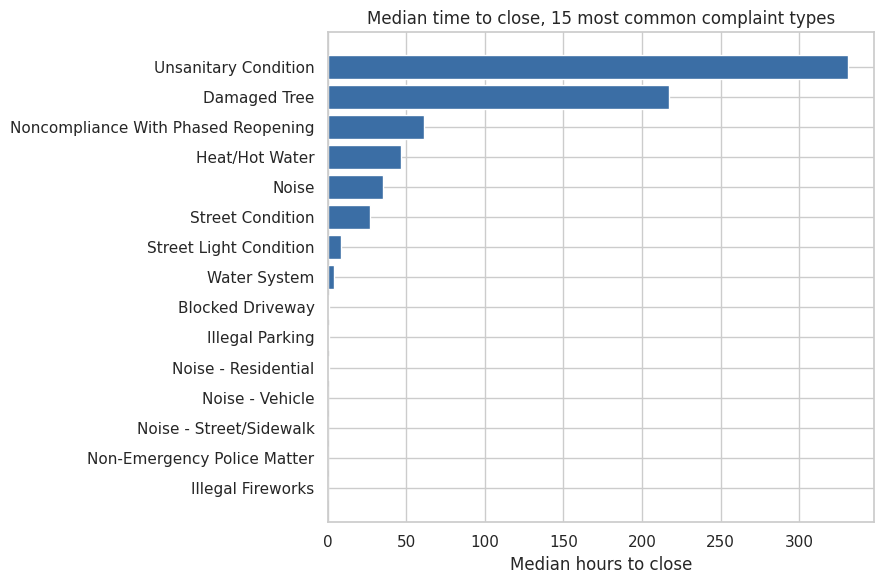

In [8]:
top = by_type.sort_values("requests", ascending=False).head(15).sort_values("median_hours")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["median_hours"], color="#3b6ea5")
ax.set_xlabel("Median hours to close")
ax.set_title("Median time to close, 15 most common complaint types")
plt.tight_layout()
plt.savefig(DATA_DIR / "median_hours_by_type.png", dpi=150)
plt.show()

In [9]:
by_borough = (df.groupby("borough")
                .agg(requests=("unique_key", "size"),
                     median_hours=("hours_to_close", "median"),
                     pct_closed_within_24h=("hours_to_close", lambda s: (s <= 24).mean() * 100))
                .round(1))
by_borough

,requests,median_hours,pct_closed_within_24h
borough,,,
BRONX,588391,4.4,64.6
BROOKLYN,732466,3.4,60.6
MANHATTAN,518409,1.4,67.1
QUEENS,598099,3.0,63.7
STATEN ISLAND,111124,9.7,53.8


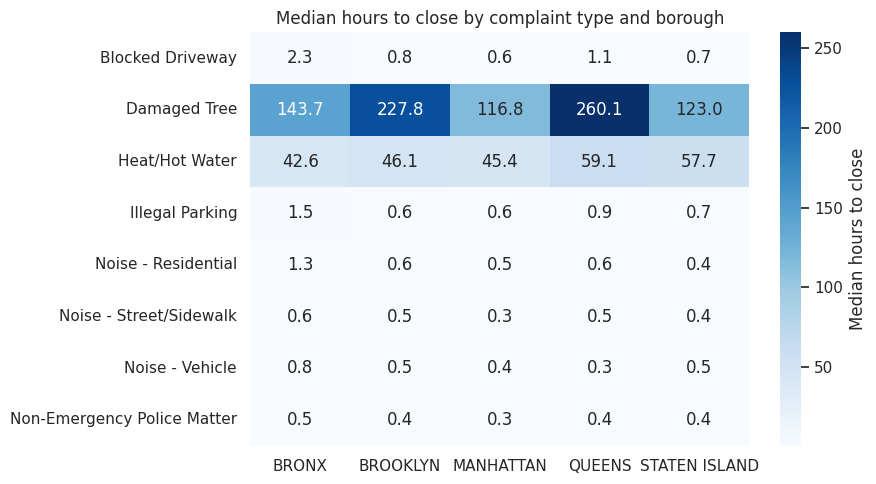

In [10]:
# Does the borough gap hold within a single complaint type, or is it just a different mix of complaints?
top_types = by_type.sort_values("requests", ascending=False).head(8).index
pivot = (df[df["complaint_type"].isin(top_types)]
         .pivot_table(index="complaint_type", columns="borough", values="hours_to_close", aggfunc="median")
         .round(1))
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Median hours to close"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Median hours to close by complaint type and borough")
plt.tight_layout()
plt.savefig(DATA_DIR / "median_hours_heatmap.png", dpi=150)
plt.show()

## 5. Export for Tableau

Tableau Public cannot connect to BigQuery, so it reads these small CSV files instead.

- `tableau_monthly_summary.csv`: one row per month, borough and complaint group.
- `tableau_zip_summary.csv`: one row per ZIP code, for the map.

The 12 most common complaint types keep their names and the rest become "Other", so the dashboard filter stays short.

In [11]:
COUNTY = {"BRONX": "Bronx County", "BROOKLYN": "Kings County", "MANHATTAN": "New York County",
          "QUEENS": "Queens County", "STATEN ISLAND": "Richmond County"}

keep = df["complaint_type"].value_counts().head(12).index
df["complaint_group"] = df["complaint_type"].where(df["complaint_type"].isin(keep), "Other")

def summarise(g):
    return g.agg(requests=("unique_key", "size"),
                 closed_requests=("hours_to_close", "count"),
                 median_hours_to_close=("hours_to_close", "median"),
                 pct_closed_within_24h=("hours_to_close", lambda s: (s <= 24).mean() * 100)).round(1)

monthly = summarise(df.groupby(["month", "borough", "complaint_group"])).reset_index()
monthly["borough"] = monthly["borough"].str.title()
monthly["county"] = monthly["borough"].str.upper().map(COUNTY)
monthly["state"] = "New York"
monthly.to_csv(DATA_DIR / "tableau_monthly_summary.csv", index=False)

zips = df[df["incident_zip"].astype("string").str.fullmatch(r"\d{5}").fillna(False)]
zip_summary = summarise(zips.groupby(["incident_zip", "borough"])).reset_index()
zip_summary = zip_summary[zip_summary["requests"] >= 100]
zip_summary["borough"] = zip_summary["borough"].str.title()
zip_summary.to_csv(DATA_DIR / "tableau_zip_summary.csv", index=False)

audit.to_csv(DATA_DIR / "data_audit.csv")
print(f"monthly summary: {len(monthly):,} rows | zip summary: {len(zip_summary):,} rows")
monthly.head()

monthly summary: 755 rows | zip summary: 194 rows


,month,borough,complaint_group,requests,closed_requests,median_hours_to_close,pct_closed_within_24h,county,state
0,2020-01-01,Bronx,Blocked Driveway,1981,1981,6.5,82.9,Bronx County,New York
1,2020-01-01,Bronx,Damaged Tree,100,62,123.3,4.0,Bronx County,New York
2,2020-01-01,Bronx,Heat/Hot Water,9495,9494,40.9,24.3,Bronx County,New York
3,2020-01-01,Bronx,Illegal Parking,1952,1952,5.7,91.0,Bronx County,New York
4,2020-01-01,Bronx,Noise - Residential,4900,4900,3.7,93.8,Bronx County,New York


## 6. Check the numbers against SQL

The clean row count here should equal `SELECT COUNT(*) FROM nyc311.requests_clean` in BigQuery, and the borough totals should match `nyc311.requests_per_capita`. Small differences in medians are expected because BigQuery's `APPROX_QUANTILES` is approximate.

If the row counts differ, the usual cause is duplicate `unique_key` rows, which this notebook drops and the SQL view does not.

**Result:** BigQuery returned 2,548,489 rows for `nyc311.requests_clean`, matching the clean row count below, and the borough totals in `nyc311.requests_per_capita` matched as well.

In [12]:
assert monthly["requests"].sum() == len(df), "summary does not add up to the clean row count"
print(f"clean rows to compare with SQL: {len(df):,}")
df.groupby("borough").size().rename("requests").to_frame()

clean rows to compare with SQL: 2,548,489


,requests
borough,
BRONX,588391
BROOKLYN,732466
MANHATTAN,518409
QUEENS,598099
STATEN ISLAND,111124



## 7. Findings

1. **Slowest complaint types:** Most requests close within hours, but tree-related requests take months. New Tree Requests took a median of 369 days to close (8,847 hours), and three of the six slowest types concern trees (New Tree Request, Dead/Dying Tree at 52 days, Illegal Tree Damage at 45 days). Root/Sewer/Sidewalk Condition (99 days) and Building/Use (80 days) were the next slowest.
2. **Borough differences:** Manhattan requests closed fastest, with a median of 1.4 hours and 67.1% closed within 24 hours. Staten Island was slowest, with a median of 9.7 hours and 53.8% closed within 24 hours. The Bronx filed the most requests per resident, about 400 per 1,000, compared with 224 per 1,000 in Staten Island.
3. **Data quality:** Of 2.59 million raw requests, 1.7% (44,650) had no valid borough and were removed. Of the remaining 2.55 million, 3.4% (85,424) had no usable close time, because the closed date was missing or earlier than the created date. Only 2 of 185 complaint types were spelled more than one way.

**Limitations:** `closed_date` records when the agency closed the ticket, which is not always when the problem was fixed. 3.8% of raw requests were closed in the same minute they were created, which likely reflects agency logging practices and pulls some medians toward zero. Borough medians also reflect each borough's mix of complaint types, so they do not by themselves show that one borough gets slower service. The data covers 2020, a pandemic year, so volumes and response times may not be typical.